<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/18_Cloud_Virtual_Environment_Threats/QLSTM_SyscallThreat_Tripathi2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QLSTM for threat detection in virtual machines: Tripathi, Upadhyay and Soni (2025) step by step

**Paper.** S. Tripathi, H. Upadhyay, J. Soni, *A Quantum LSTM-based approach to cyber threat detection in virtual environment*, The Journal of Supercomputing 81:142 (2025). DOI: [10.1007/s11227-024-06615-7](https://doi.org/10.1007/s11227-024-06615-7). Authors' code: `github.com/SarvaTripathi/QLSTM_SystemCalls`.

**What this notebook does.** It rebuilds the paper's experiment from the ground up, with a plain-language explanation of every step: a quantum long short-term memory (QLSTM) network reads a sequence of operating-system calls (the calls a process makes inside a virtual machine) and learns to predict the next call. The paper trains a classical LSTM and a QLSTM for every combination of 7 hidden sizes (2 to 14) and 10 qubit counts (1 to 10) and reports accuracy and loss curves. We repeat that grid, redraw its figures and Table 3, and then check the claims one by one. Because the authors' Windows system-call capture is not public, we use a public substitute (ADFA-LD attack traces; see the table below). Along the way the notebook reads the authors' released code line by line and reports what it **actually** trains on, which turns out to matter a great deal for how the paper's numbers should be read.

**How to run it.** Open in Google Colab, keep the normal CPU runtime (no GPU, no account, no quantum hardware), choose *Runtime, then Run all*. `FAST_MODE = True` (default, set in the configuration cell) is a class demo that finishes in about 10 minutes. `FAST_MODE = False` follows the paper's grid and its 300 epochs and takes about an hour on a CPU (we measured 67 minutes on a machine shared with several other jobs).

**What you get at the end.** The paper's figures and Table 3 redrawn with our numbers, a held-out evaluation the paper does not contain, a side-by-side table with one verdict per claim, a critical reading, and five exercises.

## The paper in one page

* **Problem.** Hypervisor-based virtual machine introspection (VMI) records the system calls of a process running in a guest VM. Malware that hooks the process changes that sequence, so the sequence is a behavioural fingerprint. The authors treat a system-call sequence as a sentence and each call as a word.
* **Decision.** *Sequence to sequence*: the first calls of a sequence are the input and the network predicts the next call at every position ("the first few system call sequences are fed as input, and the trained QLSTM model predicts the next system call"). It is a next-call predictor, not a benign/malicious classifier; the assumed use is anomaly detection when predictions fail.
* **Data.** Windows system calls of a process injected with a custom DLL malware, captured on Xen 4.12 with LibVMI/DRAKVUF; 450 standard calls are mapped to indices 0..449 (Table 2). **No data are released** ("No datasets were generated or analyzed", although the paper says "we introduce our dataset"). Size, number of processes and split are not stated.
* **Model.** Embedding (dim 8) -> QLSTM or classical LSTM (hidden 2, 4, ..., 14) -> linear -> log-softmax over the call vocabulary. In the QLSTM each of the four gates (forget, input, candidate/update, output) is a variational quantum circuit (VQC): angle encoding, one variational layer (single-qubit rotations plus a CNOT ring), Pauli-Z read-out (Figs. 4-6, 9; eq. 2a-2f). 1 to 10 qubits, PennyLane `default.qubit`, PyTorch, 300 epochs.
* **Claims.** (i) The classical LSTM is accurate for all hidden sizes (Fig. 10). (ii) QLSTM accuracy is low with 1 qubit, improves from 2 qubits, has no clear gain beyond 4, and loss keeps improving up to about 8 qubits (Figs. 11-17). (iii) QLSTMs with hidden size below the embedding size (8) struggle. (iv) Table 3: best accuracy 1.00 for hidden sizes 4 to 14 and 0.83 for hidden size 2, with losses 0.26 to 0.71. (v) QLSTM needs at least twice as many epochs as the classical LSTM, with highest accuracy after about 275 epochs and loss 0.3 after about 250 (Figs. 18-19), but ends at similar accuracy and loss (Figs. 20-21). (vi) QLSTM training is much slower on a simulator.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Private Windows system calls from a Xen VM infected by a DLL-injection malware; 450-call map | **Substitute:** ADFA-LD *attack* traces (Linux host; Adduser, Hydra-FTP, Hydra-SSH, Java-Meterpreter, Meterpreter, Web-Shell). One trace = one process. Vocabulary = all call numbers seen (90) |
| Task | Predict the next call at every position of a window | Same (`split_sequence`, windows of 3, target shifted by one) |
| Window length | Not stated in the paper; released code uses 3 | 3 |
| Training set | Not stated; the released `train()` loops `range(len(trainingdata))` over a tuple `(X, y)`, i.e. **windows 0 and 1 only** | Same as the released code: first 2 windows = 6 target calls; training accuracy = evaluation accuracy (section 2 shows the evidence) |
| Which processes | One unknown capture | `K_CLEAN` seeded random ADFA-LD attack traces whose first 5 calls contain at least 4 different calls and whose first 6 targets contain no conflicting pair (so accuracy 1.00 is reachable by the released cell and the task is not trivial); `K_ANY` unfiltered traces as a sensitivity study |
| Embedding / hidden / qubits | 8 / 2..14 / 1..10 | Same (reduced grid in FAST_MODE) |
| Circuit | Text: "strongly entangled" layer R(a,b,g) + CNOT. Released code: `AngleEmbedding` + `BasicEntanglerLayers` (RX rotations + CNOT ring), 1 layer | Released code (the only version that can be checked) |
| Optimiser | Not stated; released code: SGD, lr 0.1, one window per step, NLL loss | Same |
| Epochs | 300 | 300 (100 in FAST_MODE) |
| Simulator | PennyLane `default.qubit` | A PyTorch twin of the same circuits (checked against PennyLane to 1e-15) for speed; PennyLane is the reference |
| Recurrence | QLSTM is "very similar to classical LSTM" with recurrent state | Released cell: **no recurrence** (section 2). We run both the released cell and a genuinely recurrent QLSTM |
| Metrics | Accuracy and loss per epoch (training) | Same, plus held-out next-call accuracy, a bigram baseline and wall-clock time |
| Seeds | Not stated | `SEED = 42`, one seed per (process, hidden, qubits) |

## 0. Setup

Colab already has NumPy, pandas, scikit-learn, matplotlib and PyTorch. We add PennyLane, the framework used by the paper. The next cell does nothing when PennyLane is already installed. If Colab asks you to restart the session after it, accept, then run the notebook again from the next cell.

In [1]:
# Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch. We add PennyLane (the paper's framework).
# The cell does nothing when PennyLane is already installed (for example on a local machine).
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "requests"], check=True)
    print("Installed pennylane==0.45.1. If Colab asks you to restart the session, accept and run again from the next cell.")
else:
    print("PennyLane already available, nothing to install.")


PennyLane already available, nothing to install.


The **configuration cell** holds every tunable constant. `FAST_MODE` shrinks the grid and the number of epochs so that the whole notebook runs in about 10 minutes; set it to `False` for the paper's grid (7 hidden sizes x 10 qubit counts x 300 epochs). No quantum-hardware token is needed because the paper used a simulator.

In [2]:
# ------------------------------- configuration: every tunable constant lives here -------------------------------
SEED = 42
FAST_MODE = False      # True: about 10 minute class demo (reduced grid / epochs). False: the paper's grid and 300 epochs.
DATA_DIR = "adfa_ld_data"      # cache folder for the downloaded ADFA-LD zip
IBM_TOKEN = ""                 # not used: the paper ran PennyLane default.qubit only (no hardware), kept for the convention

# --- model / task constants taken from the paper and its released code ---
EMB_DIM   = 8          # paper: embedding dimension 8
N_STEPS   = 3          # released code: data = split_sequence(h, 3)
N_QLAYERS = 1          # released code: QLSTM default n_qlayers=1 (BasicEntanglerLayers with one layer)
LR        = 0.1        # released code: optim.SGD(lr=0.1), one window per update
PAPER_WINDOWS = 2      # what the released train() loop really uses (see section 2): len((X, y)) == 2

if FAST_MODE:
    EPOCHS       = 100                 # paper: 300
    HIDDEN_LIST  = [2, 4, 8, 14]       # paper: 2,4,...,14
    QUBIT_LIST   = [1, 2, 4, 6, 8, 10] # paper: 1..10
    K_CLEAN      = 3                   # number of substitute "processes" for the main grid
    K_ANY        = 3                   # extra processes drawn without any filtering (sensitivity study)
    REC_QUBITS   = [1, 4, 8]           # qubit counts for the recurrent-variant study (hidden 8)
    B_STREAM_LEN, B_EPOCHS, B_FAMILIES, B_SEEDS = 200, 40, 3, 1
else:
    EPOCHS       = 300
    HIDDEN_LIST  = [2, 4, 6, 8, 10, 12, 14]
    QUBIT_LIST   = list(range(1, 11))
    K_CLEAN      = 4
    K_ANY        = 3
    REC_QUBITS   = list(range(1, 11))
    B_STREAM_LEN, B_EPOCHS, B_FAMILIES, B_SEEDS = 300, 80, 6, 1
H_REC = 8              # hidden size used for the recurrent-variant study
B_HIDDEN, B_QUBITS = 14, 8   # models of the held-out study (section 9)


In [3]:
import os, io, time, math, zipfile, collections, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
from scipy.stats import spearmanr
warnings.filterwarnings("ignore", category=UserWarning)

def set_seed(s):
    torch.manual_seed(int(s)); np.random.seed(int(s) % (2**32 - 1))

set_seed(SEED)
torch.set_num_threads(max(1, min(2, os.cpu_count() or 1)))
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| epochs =", EPOCHS, "| hidden sizes", HIDDEN_LIST, "| qubits", QUBIT_LIST)


numpy 2.5.4 | pandas 3.0.6 | torch 2.14.1+cpu | pennylane 0.45.1
FAST_MODE = False | epochs = 300 | hidden sizes [2, 4, 6, 8, 10, 12, 14] | qubits [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


## 1. Data: system-call traces as "sentences"

A system call is the request a program makes to the operating system (open a file, read, write, create a process...). The ordered list of calls a process makes is its *trace*. ADFA-LD is a public host-intrusion dataset recorded on a Linux machine: normal activity, and traces of a process under six attack families. We use the **attack** traces as the stand-in for the paper's malware-infected process, one trace per "process". Each call is an integer (its number in the kernel's call table); a few are given names below only for readability, the models only see integers.

*Deviation (documented in the table above):* operating system (Linux instead of Windows), call numbering (about 300 instead of the paper's 450 standard calls) and malware (Metasploit/Hydra-style attacks instead of a DLL injection) differ. The task and the models are the same.

In [4]:
# CHOICE: the authors' Xen/DRAKVUF Windows system-call list is not public (the data-availability statement says no data).
# Public substitute: ADFA-LD, system-call traces of a Linux host under six attack families (Adduser, Hydra-FTP, Hydra-SSH,
# Java-Meterpreter, Meterpreter, Web-Shell). Each trace is one process: a sequence of integer system-call numbers.
ADFA_URLS = [
    "https://raw.githubusercontent.com/piyush-jain1/ADFA-LDPreprocessing/HEAD/ADFA-LD.zip",   # full set incl. Attack_Data_Master
    "https://github.com/piyush-jain1/ADFA-LDPreprocessing/raw/HEAD/ADFA-LD.zip",
]
ADFA_FALLBACK = "https://raw.githubusercontent.com/verazuo/a-labelled-version-of-the-ADFA-LD-dataset/HEAD/ADFA-LD.zip"  # normal traces only

def fetch(urls, dest):
    if os.path.exists(dest) and os.path.getsize(dest) > 1_000_000:
        return dest
    for u in urls:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            with open(dest, "wb") as f: f.write(r.content)
            return dest
        except Exception as e:
            print("download failed:", u, "->", repr(e)[:100])
    return None

def load_adfa(path):
    z = zipfile.ZipFile(path); out = []
    for n in sorted(z.namelist()):
        if not n.endswith(".txt"): continue
        parts = n.split("/")
        if "Attack_Data_Master" in parts:
            fam = parts[-2].rsplit("_", 1)[0]
        elif "Training_Data_Master" in parts:
            fam = "Normal"
        else:
            continue
        out.append((parts[-2] + "/" + parts[-1], fam, [int(t) for t in z.read(n).split()]))
    return out

zpath = fetch(ADFA_URLS, os.path.join(DATA_DIR, "ADFA-LD-full.zip"))
traces = load_adfa(zpath) if zpath else []
if not any(f != "Normal" for _, f, _ in traces):
    print("Attack traces unavailable: falling back to the normal ADFA-LD traces (documented deviation).")
    zpath = fetch([ADFA_FALLBACK], os.path.join(DATA_DIR, "ADFA-LD-normal.zip"))
    traces = load_adfa(zpath)
assert len(traces) > 100, "no data could be downloaded"
print(len(traces), "traces;", collections.Counter(f for _, f, _ in traces))
lens = np.array([len(t) for _, _, t in traces]); print("trace length  min/median/max:", lens.min(), int(np.median(lens)), lens.max())

# vocabulary ("word_to_ix"): every system-call number that occurs in the data, as in the released code (built from the whole list)
_fams = {f for _, f, _ in traces}
VOCAB = sorted({c for _, f, t in traces if f != "Normal" or _fams == {"Normal"} for c in t}); V = len(VOCAB); W2I = {c: i for i, c in enumerate(VOCAB)}
print("vocabulary size V =", V)
# a few Linux i386 call numbers, only to make the printouts readable (the models only ever see the integers)
NAMES = {1:"exit", 3:"read", 4:"write", 5:"open", 6:"close", 11:"execve", 33:"access", 45:"brk", 91:"munmap", 102:"socketcall",
         120:"clone", 125:"mprotect", 168:"poll", 174:"rt_sigaction", 175:"rt_sigprocmask", 192:"mmap2", 195:"stat64",
         197:"fstat64", 221:"fcntl64", 240:"futex", 252:"exit_group"}
name = lambda c: NAMES.get(c, str(c))
print("example trace", traces[0][0], "->", [name(c) for c in traces[0][2][:12]])


1579 traces; Counter({'Normal': 833, 'Hydra_SSH': 176, 'Hydra_FTP': 162, 'Java_Meterpreter': 124, 'Web_Shell': 118, 'Adduser': 91, 'Meterpreter': 75})
trace length  min/median/max: 75 229 2948
vocabulary size V = 90
example trace Adduser_1/UAD-Adduser-1-1371.txt -> ['265', 'poll', 'poll', '265', 'poll', 'poll', 'poll', '265', 'poll', '265', 'poll', 'poll']


## 2. What the released code really trains on

This is the key reading step. The authors' notebook builds its data with

```python
data = split_sequence(h, 3)        # returns (array(X), array(y))  -> a TUPLE of two arrays
...
def train(model, n_epochs, trainingdata=trainingdata, ...):
    ...
    for i in range(len(trainingdata)):                 # len of the tuple == 2
        sentence_in = prepare_sequence(trainingdata[0][i], word_to_ix)
        labels      = prepare_sequence(trainingdata[1][i], word_to_ix)
```

`len(trainingdata)` is the length of the tuple `(X, y)`, which is **2**, not the number of windows. So every epoch visits **window 0 and window 1 only**: with windows of 3 calls that is the first 5 calls of the sequence and 6 target predictions. The "accuracy" is the share of those 6 targets predicted correctly (pre-update, during the epoch) and the "loss" is the average NLL of the two windows, and nothing is held out. This also explains why the paper's accuracies take only the values 0.83 (= 5/6) and 1.00 (= 6/6) in Table 3.

A second property of the released QLSTM class: `LSTMTagger` hands it a tensor of shape `(len(sentence), 1, embedding)` while the class was built with `batch_first=True`, so it reads that as **batch = number of tokens, sequence length = 1**. Each call is therefore processed *alone* with a zero initial hidden state; no information flows from one call to the next. (The classical `nn.LSTM`, with its default `batch_first=False`, reads the same tensor as a real sequence of length 3.) A cell with no memory can only learn "current call -> next call", so its best possible accuracy on a window set is the *context-free ceiling* computed below.

The next cell reproduces both facts on our data. We keep the released behaviour for the main grid (it is what produced the paper's numbers) and add a genuinely recurrent QLSTM in section 8.

In [5]:
def split_sequence(seq, n_steps):
    """Exactly the released code: window i is seq[i:i+n] and its target is seq[i+1:i+n+1] (next call at every position)."""
    X, Y = [], []
    for i in range(len(seq)):
        end = i + n_steps
        if end > len(seq) - 1: break
        X.append(seq[i:end]); Y.append(seq[i + 1:end + 1])
    return np.array(X), np.array(Y)

demo = traces[0][2][:12]
X_demo, Y_demo = split_sequence(demo, N_STEPS)
print("stream:", demo)
print("X[0] =", X_demo[0], " y[0] =", Y_demo[0]); print("X[1] =", X_demo[1], " y[1] =", Y_demo[1])

# The released train() does:  data = split_sequence(h, 3)  ->  a TUPLE (X, y);   for i in range(len(trainingdata)): ...
trainingdata = split_sequence(traces[0][2], N_STEPS)
print("\nlen(trainingdata) =", len(trainingdata), "-> the loop 'for i in range(len(trainingdata))' visits windows i = 0 and 1 only")
print("number of windows available in the first trace:", len(trainingdata[0]), "| windows really used for training/accuracy: 2 (= 6 target tokens)")

def paper_set(seq):
    """The effective training AND evaluation set of the released code: windows 0 and 1 (tokens 0..4 of the stream)."""
    X, Y = split_sequence(list(seq[:N_STEPS + PAPER_WINDOWS]), N_STEPS)
    return torch.tensor([[W2I[c] for c in w] for w in X]), torch.tensor([[W2I[c] for c in w] for w in Y])

def ceiling(seq):
    """Best accuracy any model can reach if the next-call prediction may only look at the CURRENT call (no recurrence)."""
    X, Y = paper_set(seq); m = collections.defaultdict(collections.Counter)
    for a, b in zip(X.reshape(-1).tolist(), Y.reshape(-1).tolist()): m[a][b] += 1
    return sum(max(c.values()) for c in m.values()) / X.numel()

ceil_all = np.array([ceiling(t) for _, f, t in traces if (f != "Normal" or _fams == {"Normal"}) and len(t) >= N_STEPS + PAPER_WINDOWS + 1])
print("\ncontext-free ceiling on the first 6 targets over all traces: mean %.3f; share of traces with ceiling 1.0: %.2f"
      % (ceil_all.mean(), (ceil_all == 1).mean()))


stream: [265, 168, 168, 265, 168, 168, 168, 265, 168, 265, 168, 168]
X[0] = [265 168 168]  y[0] = [168 168 265]
X[1] = [168 168 265]  y[1] = [168 265 168]

len(trainingdata) = 2 -> the loop 'for i in range(len(trainingdata))' visits windows i = 0 and 1 only
number of windows available in the first trace: 276 | windows really used for training/accuracy: 2 (= 6 target tokens)

context-free ceiling on the first 6 targets over all traces: mean 0.850; share of traces with ceiling 1.0: 0.33


We now pick the processes. The main grid uses processes for which the first 6 targets contain no conflicting pair (the same call followed once by one call and once by another), because only then can a cell without memory reach accuracy 1.00, the value the paper reports almost everywhere. We also require at least 4 different calls among the 5 (a stream such as `54, 54, 54, 54, 54` would be trivially perfect for every model). A second set is drawn without any filter and used in section 8.

In [6]:
rng = np.random.default_rng(SEED)
valid = [i for i, (_, f, t) in enumerate(traces) if f != "Normal" and len(t) >= max(60, N_STEPS + PAPER_WINDOWS + 1)] or \
        [i for i, (_, f, t) in enumerate(traces) if len(t) >= 60]
MIN_DISTINCT = 4
clean_pool = [i for i in valid if ceiling(traces[i][2]) == 1.0 and len(set(traces[i][2][:N_STEPS + PAPER_WINDOWS])) >= MIN_DISTINCT]
# CHOICE: main grid = K_CLEAN processes whose first 5 calls contain at least MIN_DISTINCT = 4 different calls and whose first 6
# targets contain no conflicting (same call -> different next call) pair.
# Reason: the paper reports accuracy exactly 1.00 (= 6/6) for most settings, which the released (non-recurrent) cell can only
# reach on conflict-free data, and a stream such as 54,54,54,54,54 would make every model trivially perfect.
# A second set of K_ANY processes is drawn without any filter (sensitivity study, section 8).
CLEAN = [int(i) for i in rng.choice(clean_pool, size=K_CLEAN, replace=False)]
ANY   = [int(i) for i in rng.choice(valid, size=K_ANY, replace=False)]
print("pool sizes: valid", len(valid), "| conflict-free", len(clean_pool))
for tag, ids in (("CLEAN", CLEAN), ("ANY", ANY)):
    for i in ids:
        nm, fam, t = traces[i]
        print(f"{tag:5s} {nm:36s} {fam:17s} len={len(t):5d} first 5 calls: {[name(c) for c in t[:5]]} ceiling={ceiling(t):.2f}")


pool sizes: valid 746 | conflict-free 129
CLEAN Hydra_SSH_3/UAD-Hydra-SSH-3-1613.txt Hydra_SSH         len=  351 first 5 calls: ['265', '146', 'munmap', '142', '265'] ceiling=1.00
CLEAN Hydra_FTP_2/UAD-Hydra-FTP-2-9374.txt Hydra_FTP         len=  221 first 5 calls: ['172', 'read', 'open', 'stat64', 'mmap2'] ceiling=1.00
CLEAN Hydra_SSH_8/UAD-Hydra-SSH-8-8017.txt Hydra_SSH         len=  121 first 5 calls: ['write', '66', 'access', 'read', 'close'] ceiling=1.00
CLEAN Java_Meterpreter_2/UAD-Java-Meterpreter-2-19544.txt Java_Meterpreter  len=  252 first 5 calls: ['open', '266', 'mprotect', 'mmap2', 'close'] ceiling=1.00
ANY   Java_Meterpreter_7/UAD-Java-Meterpreter-7-20425.txt Java_Meterpreter  len=  855 first 5 calls: ['futex', 'futex', '78', '78', 'futex'] ceiling=0.67
ANY   Adduser_9/UAD-Adduser-9-17612.txt    Adduser           len=  826 first 5 calls: ['256', 'socketcall', '256', 'read', '256'] ceiling=0.83
ANY   Hydra_FTP_3/UAD-Hydra-FTP-3-8978.txt Hydra_FTP         len=  109 first 5 

## 3. The quantum gate circuit and a fast twin simulator

Each QLSTM gate is a small quantum circuit with the following parts (Figs. 4, 5, 9 of the paper):

1. **Data encoding.** The classical vector (one number per qubit, produced by a linear layer) becomes rotation angles: qubit *i* is rotated by RX(x_i).
2. **Variational layer.** One trainable RX rotation per qubit followed by a ring of CNOT gates that entangles neighbours (PennyLane `BasicEntanglerLayers`).
3. **Measurement.** The expectation value of Pauli-Z on every qubit gives one real number per qubit.

First the circuit in PennyLane (4 qubits for readability; the paper's Fig. 9 shows 8).

In [7]:
# ---- reference: the paper's gate circuit written in PennyLane (as in the released code) ----
def make_pl_circuit(n):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(n))                  # data encoding: RX(x_i) on wire i
        qml.BasicEntanglerLayers(weights, wires=range(n))          # variational layer: RX(w) on every wire + ring of CNOTs
        return [qml.expval(qml.PauliZ(w)) for w in range(n)]       # measurement: <Z> on every wire
    return circuit

n_demo = 4
circ = make_pl_circuit(n_demo)
print(qml.draw(circ)(torch.zeros(n_demo), torch.zeros(N_QLAYERS, n_demo)))


0: ─╭AngleEmbedding(M0)─╭BasicEntanglerLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
2: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
3: ─╰AngleEmbedding(M0)─╰BasicEntanglerLayers(M1)─┤  <Z>

M0 = 
tensor([0., 0., 0., 0.])
M1 = 
tensor([[0., 0., 0., 0.]])


Training the full grid with `default.qubit` is slow because PyTorch calls PennyLane circuit by circuit. For speed we implement **the same four circuits as one batched state-vector computation in PyTorch** (`vqc_twin`). The next cell proves the two agree on values and gradients (differences at the level of 1e-16) and measures the speed-up. All grid results use the twin.

In [8]:
# ---- fast twin simulator (pure PyTorch state vector, identical maths) ----
# default.qubit costs ~10 s per training step for the full grid on a CPU; the twin simulates the four gate circuits at once.
_cache = {}
def _tables(n):
    if n not in _cache:
        idx = np.arange(2 ** n)
        bits = (idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1               # wire 0 = most significant bit
        zsign = torch.tensor(1.0 - 2.0 * bits, dtype=torch.float32)
        pairs = [] if n == 1 else ([(0, 1)] if n == 2 else [(i, (i + 1) % n) for i in range(n)])  # PennyLane's CNOT ring
        perm = idx.copy()
        for c, t in pairs:
            flipped = idx ^ (((idx >> (n - 1 - c)) & 1) << (n - 1 - t)); perm = perm[flipped]
        _cache[n] = (zsign, torch.tensor(perm, dtype=torch.long))
    return _cache[n]

def vqc_twin(inputs, weights, dtype=torch.float32):
    """inputs (G,B,n) angles, weights (G,L,n) -> (G,B,n) expectation values <Z_i> of G independent circuits."""
    G, B, n = inputs.shape; L = weights.shape[1]
    cdt = torch.complex64 if dtype == torch.float32 else torch.complex128
    zsign, perm = _tables(n); zsign = zsign.to(dtype)
    x = inputs.to(dtype)
    q = torch.stack([torch.cos(x / 2).to(cdt), -1j * torch.sin(x / 2).to(cdt)], dim=-1)   # RX(x)|0> per wire: (G,B,n,2)
    psi = q[:, :, 0, :]
    for k in range(1, n):                                                                  # product state of the encoding layer
        psi = (psi.unsqueeze(-1) * q[:, :, k, :].unsqueeze(-2)).reshape(G, B, -1)
    for l in range(L):
        w = weights[:, l, :].to(dtype)
        cc, ss = torch.cos(w / 2).to(cdt), -1j * torch.sin(w / 2).to(cdt)
        M = torch.stack([torch.stack([cc, ss], -1), torch.stack([ss, cc], -1)], -2)       # (G,n,2,2) RX matrices
        for k in range(n):
            psi = torch.einsum('gij,gbajc->gbaic', M[:, k], psi.reshape(G, B, 2 ** k, 2, 2 ** (n - k - 1))).reshape(G, B, -1)
        if n > 1: psi = psi[..., perm]                                                     # CNOT ring
    return (psi.real ** 2 + psi.imag ** 2) @ zsign

# ---- proof that the twin equals PennyLane: values and gradients, float64 ----
set_seed(SEED); rows = []
for n in (1, 2, 3, 5, 8):
    L = 2; ckt = make_pl_circuit(n)
    x = torch.rand(4, 3, n, dtype=torch.float64) * 3
    w = (torch.rand(4, L, n, dtype=torch.float64) * 2 * math.pi).requires_grad_()
    ref = torch.stack([torch.stack([torch.stack(ckt(x[g, b], w[g])) for b in range(3)]) for g in range(4)])
    tw = vqc_twin(x, w, dtype=torch.float64)
    g1 = torch.autograd.grad(ref.sum(), w)[0]; g2 = torch.autograd.grad(tw.sum(), w)[0]
    rows.append({"qubits": n, "max |value diff|": float((ref - tw).abs().max()), "max |gradient diff|": float((g1 - g2).abs().max())})
print(pd.DataFrame(rows).to_string(index=False))

# ---- speed: one forward+backward of the four gate circuits for a window of 3 tokens, 8 qubits ----
n = 8; ckt = make_pl_circuit(n); xs = torch.rand(4, 3, n); ws = torch.rand(4, 1, n).requires_grad_()
t0 = time.time()
for _ in range(3):
    out = torch.stack([torch.stack([torch.stack(ckt(xs[g, b], ws[g])) for b in range(3)]) for g in range(4)]); out.sum().backward()
t_pl = (time.time() - t0) / 3
t0 = time.time()
for _ in range(30):
    vqc_twin(xs, ws).sum().backward()
t_tw = (time.time() - t0) / 30
print(f"PennyLane default.qubit: {t_pl*1000:.0f} ms per step | twin: {t_tw*1000:.1f} ms per step | speed-up x{t_pl/t_tw:.0f}")


 qubits  max |value diff|  max |gradient diff|
      1      0.000000e+00         4.440892e-16
      2      1.110223e-16         4.440892e-16
      3      1.110223e-16         6.661338e-16
      5      2.359224e-16         3.885781e-16
      8      6.383782e-16         3.469447e-16


PennyLane default.qubit: 287 ms per step | twin: 7.1 ms per step | speed-up x40


## 4. The QLSTM, the classical LSTM and the paper's training loop

The QLSTM cell follows eq. (2a-2f): the concatenation `v_t = [h_(t-1), x_t]` goes through a classical linear layer down to *n_qubits* numbers, through the four gate circuits, and a linear layer back up to *hidden* numbers; sigmoid (forget, input, output) and tanh (candidate) turn them into gate values; then `c_t = f*c_(t-1) + i*g` and `h_t = o*tanh(c_t)`. As in the released code the two linear layers are shared by the four gates. `recurrent=False` is the released behaviour (each call alone), `recurrent=True` carries the hidden state across the calls of a window.

`train_paper` is the released loop: SGD with learning rate 0.1, one window per update, negative log-likelihood loss, accuracy and loss recorded per epoch on the same windows. The last lines train one classical and one quantum model for 30 epochs as a smoke test.

In [9]:
class QLSTM(nn.Module):
    """QLSTM cell of the released code. The four gates (forget, input, update, output) each hold one VQC; the classical layers
    clayer_in (concat(h,x) -> n_qubits) and clayer_out (n_qubits -> hidden) are SHARED by the four gates, as in the released code.
    recurrent=False reproduces the released behaviour (see section 2): every token is processed alone with h0=c0=0.
    recurrent=True runs a genuine recurrence over the T tokens of a window."""
    def __init__(self, input_size, hidden_size, n_qubits, n_qlayers=1, recurrent=False):
        super().__init__()
        self.H, self.recurrent = hidden_size, recurrent
        self.clayer_in = nn.Linear(input_size + hidden_size, n_qubits)
        self.clayer_out = nn.Linear(n_qubits, hidden_size)
        self.vqc_weights = nn.Parameter(torch.rand(4, n_qlayers, n_qubits) * 2 * math.pi)   # TorchLayer default init U(0, 2 pi)

    def step(self, x_t, h, c):
        y = self.clayer_in(torch.cat([h, x_t], dim=1))                                      # v_t = [h_{t-1}, x_t]
        q = vqc_twin(y.unsqueeze(0).expand(4, -1, -1), self.vqc_weights)                    # (4,B,n_qubits)
        o = self.clayer_out(q)                                                              # (4,B,H)
        f, i, g, o_ = torch.sigmoid(o[0]), torch.sigmoid(o[1]), torch.tanh(o[2]), torch.sigmoid(o[3])
        c = f * c + i * g                                                                   # eq. (2e)
        return o_ * torch.tanh(c), c                                                        # eq. (2f)

    def forward(self, x):                                   # x: (B, T, E)
        B, T, E = x.shape
        if not self.recurrent:
            z = torch.zeros(B * T, self.H)
            return self.step(x.reshape(B * T, E), z, z)[0].reshape(B, T, self.H)
        h = c = torch.zeros(B, self.H); outs = []
        for t in range(T):
            h, c = self.step(x[:, t], h, c); outs.append(h)
        return torch.stack(outs, 1)


class Tagger(nn.Module):
    """Embedding -> (classical LSTM | QLSTM) -> linear -> log-softmax over the V system calls (LSTMTagger of the released code)."""
    def __init__(self, emb, hidden, vocab, n_qubits=0, recurrent=False):
        super().__init__()
        self.n_qubits = n_qubits
        self.emb = nn.Embedding(vocab, emb)
        self.rnn = QLSTM(emb, hidden, n_qubits, N_QLAYERS, recurrent) if n_qubits > 0 else nn.LSTM(emb, hidden, batch_first=True)
        self.out = nn.Linear(hidden, vocab)

    def forward(self, tok):                                 # tok: (B,T) or (T,)
        single = tok.dim() == 1
        if single: tok = tok.unsqueeze(0)
        e = self.emb(tok)
        o = self.rnn(e) if self.n_qubits > 0 else self.rnn(e)[0]
        logp = F.log_softmax(self.out(o), dim=-1)
        return logp[0] if single else logp


def train_paper(model, X, Y, epochs, lr=LR):
    """The released train(): SGD lr 0.1, ONE window per update, NLL loss; loss = mean over windows, accuracy = share of correct
    next-call predictions over the windows, both recorded during the epoch (pre-update predictions), no held-out data."""
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    hist_loss, hist_acc = [], []
    for ep in range(epochs):
        losses, hits = [], 0
        for i in range(len(X)):
            model.zero_grad()
            logp = model(X[i]); loss = F.nll_loss(logp, Y[i]); loss.backward(); opt.step()
            losses.append(float(loss)); hits += int((logp.argmax(-1) == Y[i]).sum())
        hist_loss.append(float(np.mean(losses))); hist_acc.append(hits / Y.numel())
    return np.array(hist_loss), np.array(hist_acc)

# smoke test: one classical and one quantum model on the first CLEAN process
Xp, Yp = paper_set(traces[CLEAN[0]][2])
print("training set: inputs", Xp.tolist(), "-> targets", Yp.tolist())
for q in (0, 4):
    set_seed(SEED); m = Tagger(EMB_DIM, 8, V, q); t0 = time.time()
    hl, ha = train_paper(m, Xp, Yp, 30)
    print(("classical LSTM" if q == 0 else f"QLSTM {q} qubits"), "| 30 epochs: loss %.3f -> %.3f, acc %.2f -> %.2f | %.1f s" % (hl[0], hl[-1], ha[0], ha[-1], time.time() - t0))


training set: inputs [[77, 44, 30], [44, 30, 43]] -> targets [[44, 30, 43], [30, 43, 77]]


classical LSTM | 30 epochs: loss 4.650 -> 1.881, acc 0.00 -> 0.33 | 4.9 s


QLSTM 4 qubits | 30 epochs: loss 4.362 -> 2.727, acc 0.00 -> 0.33 | 0.7 s


## 5. The main grid: classical LSTM and QLSTM, every hidden size and qubit count

For each selected process we train one classical LSTM per hidden size (qubits = 0 in the tables) and one QLSTM per (hidden size, qubit count), `EPOCHS` epochs each, with the released cell. This is the experiment behind Figs. 10-17 and Table 3. The progress lines show the time per process.

In [10]:
def run_grid(trace_ids, hidden_list, qubit_list, recurrent, tag):
    res = {}
    for ti, tid in enumerate(trace_ids):
        X, Y = paper_set(traces[tid][2]); t_start = time.time()
        for h in hidden_list:
            for q in ([0] + list(qubit_list)) if not recurrent else list(qubit_list):
                set_seed(SEED + 7919 * ti + 101 * h + q)
                m = Tagger(EMB_DIM, h, V, q, recurrent=recurrent); t0 = time.time()
                hl, ha = train_paper(m, X, Y, EPOCHS)
                res[(tid, h, q)] = (hl, ha, time.time() - t0)
        print(f"[{tag}] process {ti+1}/{len(trace_ids)} ({traces[tid][0]}) done in {(time.time()-t_start)/60:.1f} min")
    return res

t_all = time.time()
RES_REL = run_grid(CLEAN, HIDDEN_LIST, QUBIT_LIST, recurrent=False, tag="released QLSTM + classical")
print(f"grid finished in {(time.time()-t_all)/60:.1f} min; {len(RES_REL)} trained models")

def to_df(res, mode):
    rows = []
    for (tid, h, q), (hl, ha, sec) in res.items():
        rows.append(dict(trace=tid, hidden=h, qubits=q, mode=mode, final_acc=ha[-1], final_loss=hl[-1], best_acc=ha.max(), seconds=sec))
    return pd.DataFrame(rows)
DF = to_df(RES_REL, "released")


[released QLSTM + classical] process 1/4 (Hydra_SSH_3/UAD-Hydra-SSH-3-1613.txt) done in 6.9 min


[released QLSTM + classical] process 2/4 (Hydra_FTP_2/UAD-Hydra-FTP-2-9374.txt) done in 10.1 min


[released QLSTM + classical] process 3/4 (Hydra_SSH_8/UAD-Hydra-SSH-8-8017.txt) done in 10.3 min


[released QLSTM + classical] process 4/4 (Java_Meterpreter_2/UAD-Java-Meterpreter-2-19544.txt) done in 10.9 min
grid finished in 38.3 min; 308 trained models


## 6. Figures 10-17 and Table 3, redrawn

*Fig. 10 analogue.* Accuracy and loss of the classical LSTM by hidden size (mean and standard deviation over the processes).

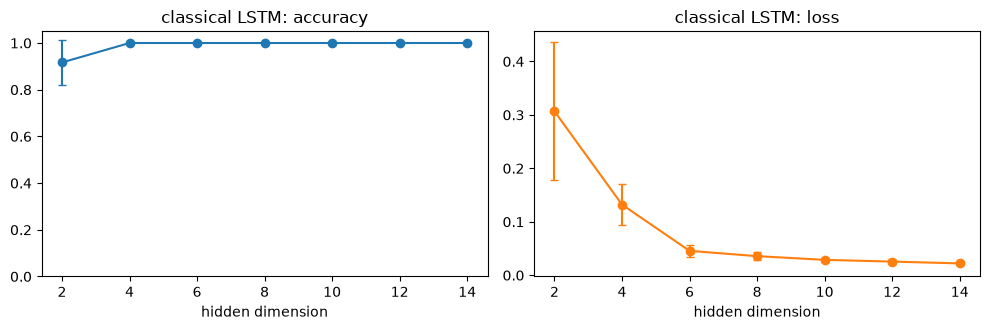

          acc  acc_sd   loss  loss_sd
hidden                               
2       0.917   0.096  0.307    0.129
4       1.000   0.000  0.132    0.039
6       1.000   0.000  0.046    0.011
8       1.000   0.000  0.036    0.008
10      1.000   0.000  0.029    0.004
12      1.000   0.000  0.026    0.005
14      1.000   0.000  0.022    0.004


In [11]:
# ---- Fig. 10 analogue: classical LSTM accuracy and loss by hidden dimension (mean +- std over the processes) ----
cl = DF[DF.qubits == 0].groupby("hidden").agg(acc=("final_acc", "mean"), acc_sd=("final_acc", "std"), loss=("final_loss", "mean"), loss_sd=("final_loss", "std")).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].errorbar(cl.index, cl.acc, cl.acc_sd, marker="o", capsize=3); ax[0].set_ylim(0, 1.05); ax[0].set_title("classical LSTM: accuracy"); ax[0].set_xlabel("hidden dimension")
ax[1].errorbar(cl.index, cl.loss, cl.loss_sd, marker="o", capsize=3, color="C1"); ax[1].set_title("classical LSTM: loss"); ax[1].set_xlabel("hidden dimension")
plt.tight_layout(); plt.show()
print(cl.round(3).to_string())


*Figs. 11-17 analogue.* QLSTM accuracy and loss against the number of qubits, one curve per hidden size, and the same numbers as heat maps.

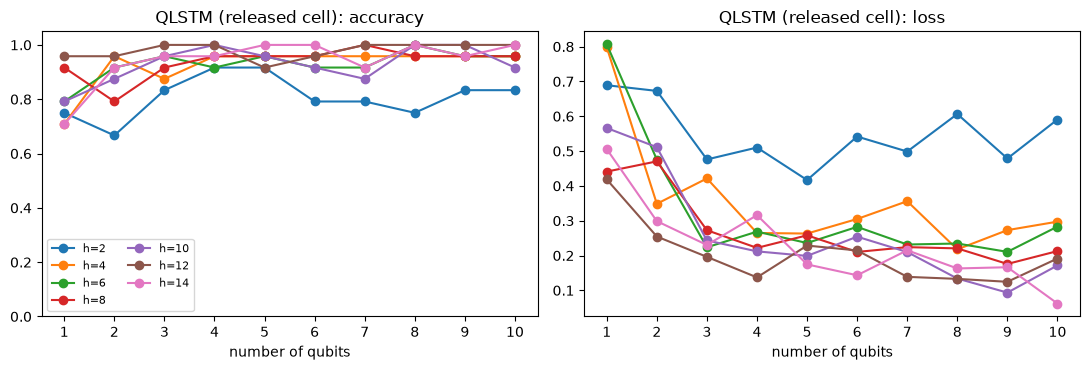

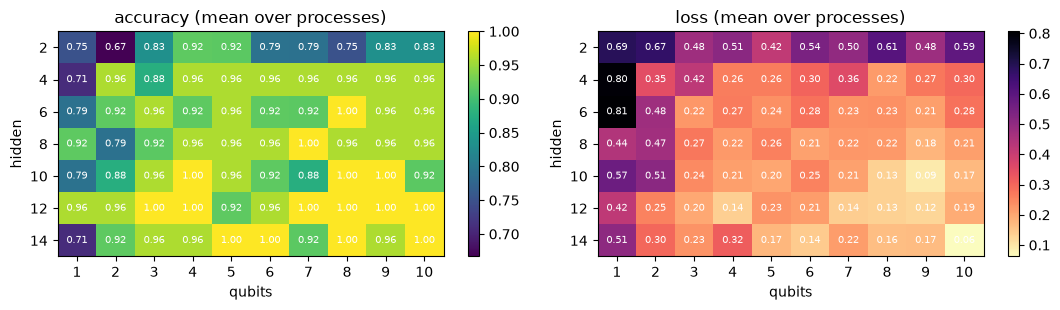

In [12]:
# ---- Figs. 11-17 analogue: QLSTM accuracy and loss by number of qubits, one curve per hidden dimension ----
qd = DF[DF.qubits > 0].groupby(["hidden", "qubits"]).agg(acc=("final_acc", "mean"), loss=("final_loss", "mean")).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for h, g in qd.groupby("hidden"):
    ax[0].plot(g.qubits, g.acc, marker="o", label=f"h={h}"); ax[1].plot(g.qubits, g.loss, marker="o", label=f"h={h}")
ax[0].set_title("QLSTM (released cell): accuracy"); ax[1].set_title("QLSTM (released cell): loss")
for a in ax: a.set_xlabel("number of qubits"); a.set_xticks(QUBIT_LIST)
ax[0].set_ylim(0, 1.05); ax[0].legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, col, ttl in zip(ax, ("acc", "loss"), ("accuracy (mean over processes)", "loss (mean over processes)")):
    pv = qd.pivot(index="hidden", columns="qubits", values=col)
    im = a.imshow(pv.values, aspect="auto", cmap="viridis" if col == "acc" else "magma_r")
    a.set_xticks(range(len(pv.columns))); a.set_xticklabels(pv.columns); a.set_yticks(range(len(pv.index))); a.set_yticklabels(pv.index)
    a.set_xlabel("qubits"); a.set_ylabel("hidden"); a.set_title(ttl); plt.colorbar(im, ax=a)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]): a.text(j, i, f"{pv.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=7)
plt.tight_layout(); plt.show()


*Table 3 analogue.* For each hidden size, the qubit count with the best final result (highest accuracy, ties broken by lower loss), chosen separately for each process, then averaged. The paper's values sit next to ours. Accuracy can only take multiples of 1/6 per process, so averages over `K_CLEAN` processes are multiples of 1/(6 K).

In [13]:
# ---- Table 3 analogue: for each hidden dimension the number of qubits with the best result (per process, then averaged) ----
PAPER_T3 = {2: (9, 0.83, 0.709), 4: (10, 1.00, 0.383), 6: (10, 1.00, 0.374), 8: (8, 1.00, 0.264), 10: (8, 1.00, 0.267), 12: (10, 1.00, 0.309), 14: (8, 1.00, 0.305)}
rows = []
for h in HIDDEN_LIST:
    best = []
    for tid, g in DF[(DF.hidden == h) & (DF.qubits > 0)].groupby("trace"):
        b = g.sort_values(["final_acc", "final_loss"], ascending=[False, True]).iloc[0]; best.append((b.qubits, b.final_acc, b.final_loss))
    best = np.array(best); pq, pa, pl = PAPER_T3[h]
    rows.append({"hidden": h, "paper qubits": pq, "paper acc": pa, "paper loss": pl, "notebook qubits (median)": float(np.median(best[:, 0])),
                 "notebook acc": best[:, 1].mean(), "notebook loss": best[:, 2].mean()})
T3 = pd.DataFrame(rows); print(T3.round(3).to_string(index=False))


 hidden  paper qubits  paper acc  paper loss  notebook qubits (median)  notebook acc  notebook loss
      2             9       0.83       0.709                       5.0         0.958          0.257
      4            10       1.00       0.383                       8.5         1.000          0.107
      6            10       1.00       0.374                       5.5         1.000          0.098
      8             8       1.00       0.264                       5.0         1.000          0.098
     10             8       1.00       0.267                       7.0         1.000          0.053
     12            10       1.00       0.309                       8.0         1.000          0.068
     14             8       1.00       0.305                       6.5         1.000          0.053


## 7. Epochs to converge and run time (Figs. 18-21)

The paper compares a classical LSTM and the best QLSTM of the same hidden size (12 hidden units, 10 qubits) epoch by epoch and states that the QLSTM needs at least twice as many epochs to reach the same accuracy and loss. We draw the same comparison and count the epoch at which the loss first falls to 0.3 (the value the paper quotes) and the epoch at which accuracy first reaches 0.99. A value of `EPOCHS + 1` means 'never reached'. Then the training time of both families.

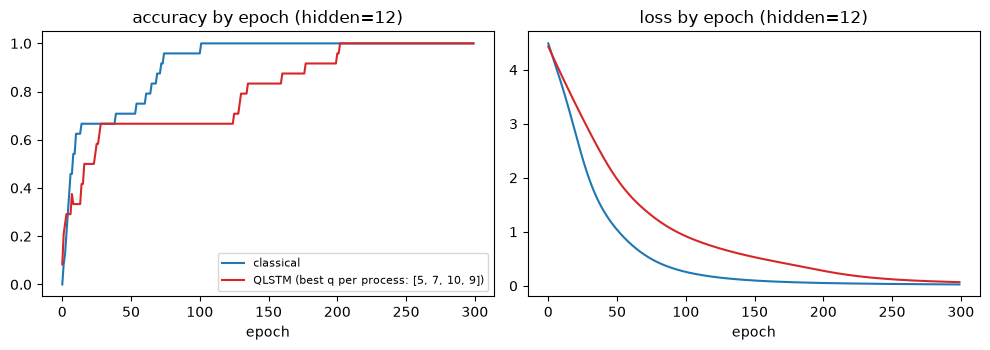

   classical: epoch loss<=0.3  QLSTM: epoch loss<=0.3  classical: epoch acc>=0.99  QLSTM: epoch acc>=0.99
0                         107                     217                         102                     203
1                          86                     210                          66                     201
2                         107                     162                          75                     136
3                          84                     167                          70                     131

mean:
 classical: epoch loss<=0.3     96.0
QLSTM: epoch loss<=0.3        189.0
classical: epoch acc>=0.99     78.2
QLSTM: epoch acc>=0.99        167.8 
(value 301 means 'never reached within 300 epochs')


In [14]:
# ---- Figs. 18-21 analogue: accuracy/loss by epoch, classical LSTM vs the best QLSTM of the same hidden dimension ----
H_REF = 12 if 12 in HIDDEN_LIST else max(HIDDEN_LIST)
curves = {"classical": [], "qlstm": []}; best_q = []
for tid in CLEAN:
    cand = [(RES_REL[(tid, H_REF, q)][1][-1], -RES_REL[(tid, H_REF, q)][0][-1], q) for q in QUBIT_LIST]
    q_best = max(cand)[2]; best_q.append(q_best)
    curves["classical"].append(RES_REL[(tid, H_REF, 0)][:2]); curves["qlstm"].append(RES_REL[(tid, H_REF, q_best)][:2])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for k, (lab, col) in enumerate((("classical", "C0"), ("qlstm", "C3"))):
    L = np.mean([c[0] for c in curves[lab]], 0); A = np.mean([c[1] for c in curves[lab]], 0)
    ax[0].plot(A, color=col, label=lab if lab == "classical" else f"QLSTM (best q per process: {best_q})"); ax[1].plot(L, color=col, label=lab)
ax[0].set_title(f"accuracy by epoch (hidden={H_REF})"); ax[1].set_title(f"loss by epoch (hidden={H_REF})")
for a in ax: a.set_xlabel("epoch")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

def first_epoch(arr, cond):
    idx = np.where(cond(arr))[0]; return int(idx[0]) + 1 if len(idx) else EPOCHS + 1       # censored at EPOCHS+1 if never reached
E = pd.DataFrame({
    "classical: epoch loss<=0.3": [first_epoch(c[0], lambda a: a <= 0.3) for c in curves["classical"]],
    "QLSTM: epoch loss<=0.3":     [first_epoch(c[0], lambda a: a <= 0.3) for c in curves["qlstm"]],
    "classical: epoch acc>=0.99": [first_epoch(c[1], lambda a: a >= 0.99) for c in curves["classical"]],
    "QLSTM: epoch acc>=0.99":     [first_epoch(c[1], lambda a: a >= 0.99) for c in curves["qlstm"]]})
print(E.to_string()); print("\nmean:\n", E.mean().round(1).to_string(), "\n(value", EPOCHS + 1, "means 'never reached within", EPOCHS, "epochs')")


mean seconds per model (300 epochs): classical 2.47 s | QLSTM 7.94 s | ratio x3.2


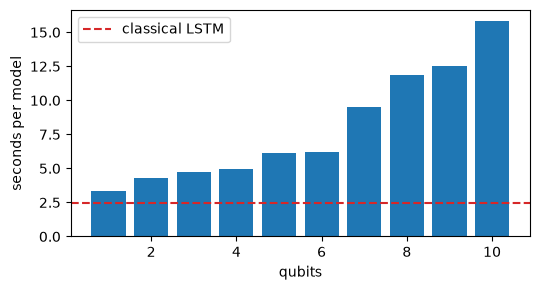

In [15]:
# ---- training time: classical LSTM vs QLSTM (PyTorch twin simulator) ----
tm = DF.groupby(DF.qubits.map(lambda q: "classical LSTM" if q == 0 else "QLSTM")).seconds.mean()
tq = DF[DF.qubits > 0].groupby("qubits").seconds.mean()
print("mean seconds per model (%d epochs): classical %.2f s | QLSTM %.2f s | ratio x%.1f" % (EPOCHS, tm["classical LSTM"], tm["QLSTM"], tm["QLSTM"] / tm["classical LSTM"]))
fig, ax = plt.subplots(figsize=(5.5, 3)); ax.bar(tq.index, tq.values); ax.axhline(tm["classical LSTM"], color="C3", ls="--", label="classical LSTM")
ax.set_xlabel("qubits"); ax.set_ylabel("seconds per model"); ax.legend(); plt.tight_layout(); plt.show()


## 8. Does the missing recurrence matter? A recurrent QLSTM

The released cell sees each call alone. Here we compare it with a QLSTM that really carries `(h, c)` across the three calls of a window, on processes drawn **without** the conflict filter (so some windows contain a call followed by two different calls, which no memory-less model can fit). For each qubit count the plot shows the final training accuracy of both cells, the context-free ceiling that bounds the released cell, and the classical LSTM. The same circuits, the same loop, only the wiring of the time axis differs.

[ANY released] process 1/3 (Java_Meterpreter_7/UAD-Java-Meterpreter-7-20425.txt) done in 1.2 min


[ANY released] process 2/3 (Adduser_9/UAD-Adduser-9-17612.txt) done in 1.3 min


[ANY released] process 3/3 (Hydra_FTP_3/UAD-Hydra-FTP-3-8978.txt) done in 1.4 min


[ANY recurrent] process 1/3 (Java_Meterpreter_7/UAD-Java-Meterpreter-7-20425.txt) done in 3.3 min


[ANY recurrent] process 2/3 (Adduser_9/UAD-Adduser-9-17612.txt) done in 3.0 min


[ANY recurrent] process 3/3 (Hydra_FTP_3/UAD-Hydra-FTP-3-8978.txt) done in 3.5 min
finished in 13.6 min
        ceiling  classical  released  recurrent
qubits                                         
1         0.778      0.944     0.778      0.778
2         0.778      0.944     0.667      0.889
3         0.778      0.944     0.778      0.889
4         0.778      0.944     0.778      0.722
5         0.778      0.944     0.778      0.889
6         0.778      0.944     0.778      0.889
7         0.778      0.944     0.778      0.778
8         0.778      0.944     0.778      0.889
9         0.778      0.944     0.778      0.944
10        0.778      0.944     0.778      0.944


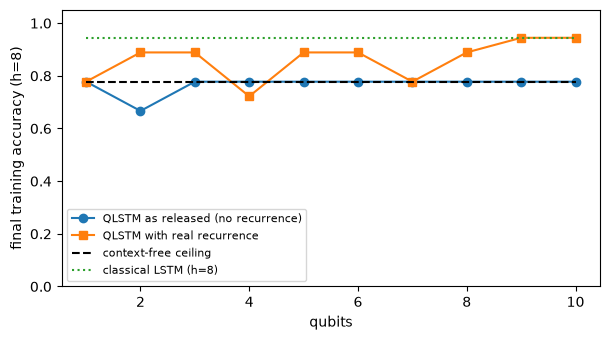

In [16]:
# ---- sensitivity: unfiltered processes (some contain a conflicting pair such as call A followed by A once and by B once) ----
# Released (non-recurrent) cell vs a genuinely recurrent QLSTM (same circuits, hidden state carried across the 3 tokens).
H_R = H_REC
t0 = time.time()
RES_ANY_REL = run_grid(ANY, [H_R], REC_QUBITS, recurrent=False, tag="ANY released")
RES_ANY_REC = run_grid(ANY, [H_R], REC_QUBITS, recurrent=True,  tag="ANY recurrent")
print(f"finished in {(time.time()-t0)/60:.1f} min")
rows = []
for tid in ANY:
    cf = ceiling(traces[tid][2])
    for q in REC_QUBITS:
        rows.append(dict(trace=tid, qubits=q, ceiling=cf, classical=RES_ANY_REL[(tid, H_R, 0)][1][-1],
                         released=RES_ANY_REL[(tid, H_R, q)][1][-1], recurrent=RES_ANY_REC[(tid, H_R, q)][1][-1]))
S = pd.DataFrame(rows)
summary = S.groupby("qubits")[["ceiling", "classical", "released", "recurrent"]].mean()
print(summary.round(3).to_string())
fig, ax = plt.subplots(figsize=(6.2, 3.5))
ax.plot(summary.index, summary.released, marker="o", label="QLSTM as released (no recurrence)")
ax.plot(summary.index, summary.recurrent, marker="s", label="QLSTM with real recurrence")
ax.plot(summary.index, summary.ceiling, "k--", label="context-free ceiling"); ax.plot(summary.index, summary.classical, ":", color="C2", label=f"classical LSTM (h={H_R})")
ax.set_xlabel("qubits"); ax.set_ylabel(f"final training accuracy (h={H_R})"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8); plt.tight_layout(); plt.show()


## 9. A proper evaluation the paper does not contain: held-out next-call prediction

Because the paper trains and scores on the same 6 targets, its accuracy says how well a model **memorises** five calls, not how well it predicts a process it has not seen. Here we take a longer stretch of one trace per attack family, train on the first 70% of its windows, leave a gap, and score on the last windows (never used for fitting). Simple count-based baselines are included: always predict the most frequent next call, and a bigram table (current call -> its most frequent next call in training). Adam with mini-batches replaces the per-window SGD (marked `# CHOICE:` in the code) since hundreds of windows are used.

  done Adduser_5/UAD-Adduser-5-1613.txt (2.4 min elapsed)


  done Hydra_FTP_6/UAD-Hydra-FTP-62783.txt (4.4 min elapsed)


  done Hydra_SSH_3/UAD-Hydra-SSH-3-6511.txt (6.6 min elapsed)


  done Java_Meterpreter_1/UAD-Java-Meterpreter-1-2311.txt (8.7 min elapsed)


  done Meterpreter_6/UAD-Meterpreter-6-1371.txt (11.9 min elapsed)


  done Web_Shell_1/UAD-WS1-2311.txt (15.1 min elapsed)
stream length 300 calls, 6 attack families, 1 seed(s), 80 epochs

                                                   test_acc  test_sd  train_acc  seconds
model                                                                                   
majority call                                         0.427    0.167        NaN    0.000
bigram table (current call -> most frequent next)     0.459    0.144        NaN    0.000
classical LSTM                                        0.440    0.168      0.513    7.284
QLSTM as released (8q)                                0.469    0.145      0.440   53.086
QLSTM recurrent (8q)                                  0.415    0.153      0.502   90.558


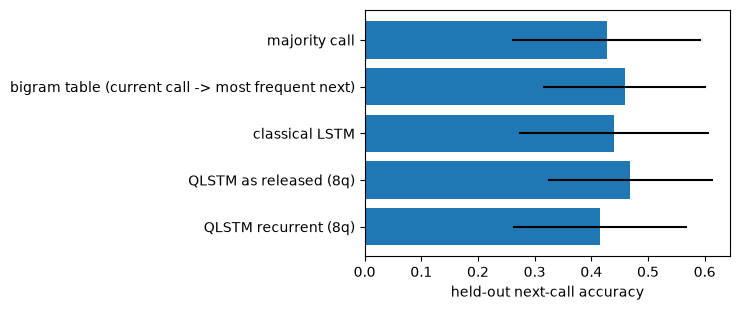

In [17]:
# ---- a proper evaluation: long stream, chronological split, held-out next-call accuracy ----
# CHOICE: Adam (lr 0.01) with mini-batches of 16 windows instead of the released per-window SGD, because a few hundred windows are used.
def make_stream(tid, length):
    return [W2I[c] for c in traces[tid][2][:length]]

def windows(stream):
    X, Y = split_sequence(stream, N_STEPS); return torch.tensor(X), torch.tensor(Y)

def heldout_run(stream, h, q, recurrent, seed, epochs):
    X, Y = windows(stream); n = len(X); a = int(0.7 * n)
    Xtr, Ytr = X[:a], Y[:a]; Xte, Yte = X[a + N_STEPS:], Y[a + N_STEPS:]           # gap of N_STEPS windows: no shared tokens
    set_seed(seed); m = Tagger(EMB_DIM, h, V, q, recurrent=recurrent); opt = torch.optim.Adam(m.parameters(), lr=0.02)
    t0 = time.time(); g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr), generator=g)
        for b in range(0, len(Xtr), 16):
            idx = perm[b:b + 16]; opt.zero_grad()
            F.nll_loss(m(Xtr[idx]).reshape(-1, V), Ytr[idx].reshape(-1)).backward(); opt.step()
    with torch.no_grad():
        acc = lambda X_, Y_: float((m(X_).argmax(-1) == Y_).float().mean())
        return acc(Xtr, Ytr), acc(Xte, Yte), time.time() - t0

def count_baselines(stream):
    X, Y = windows(stream); n = len(X); a = int(0.7 * n)
    Xtr, Ytr, Xte, Yte = X[:a], Y[:a], X[a + N_STEPS:], Y[a + N_STEPS:]
    uni = collections.Counter(Ytr.reshape(-1).tolist()).most_common(1)[0][0]
    big = collections.defaultdict(collections.Counter)
    for u, v in zip(Xtr.reshape(-1).tolist(), Ytr.reshape(-1).tolist()): big[u][v] += 1
    pred = lambda u: big[u].most_common(1)[0][0] if u in big else uni
    return (float((Yte == uni).float().mean()), float(np.mean([pred(u) == v for u, v in zip(Xte.reshape(-1).tolist(), Yte.reshape(-1).tolist())])))

# seeded random trace per family (not simply the first one)
rngB = np.random.default_rng(SEED + 1); B_IDS = []
for fam in sorted({f for _, f, _ in traces if f != "Normal"})[:B_FAMILIES]:
    cand = [i for i, (_, f, t) in enumerate(traces) if f == fam and len(t) >= B_STREAM_LEN]
    B_IDS.append(int(rngB.choice(cand)))
rows = []; t0 = time.time()
for tid in B_IDS:
    st = make_stream(tid, B_STREAM_LEN); maj, big = count_baselines(st)
    rows.append(dict(trace=tid, family=traces[tid][1], model="majority call", test_acc=maj, train_acc=np.nan, seconds=0))
    rows.append(dict(trace=tid, family=traces[tid][1], model="bigram table (current call -> most frequent next)", test_acc=big, train_acc=np.nan, seconds=0))
    for sd in range(B_SEEDS):
        for lab, h, q, rec in (("classical LSTM", B_HIDDEN, 0, False), (f"QLSTM as released ({B_QUBITS}q)", B_HIDDEN, B_QUBITS, False),
                               (f"QLSTM recurrent ({B_QUBITS}q)", B_HIDDEN, B_QUBITS, True)):
            tr_a, te_a, sec = heldout_run(st, h, q, rec, SEED + 31 * sd + tid, B_EPOCHS)
            rows.append(dict(trace=tid, family=traces[tid][1], model=lab, test_acc=te_a, train_acc=tr_a, seconds=sec))
    print("  done", traces[tid][0], f"({(time.time()-t0)/60:.1f} min elapsed)")
HB = pd.DataFrame(rows)
summ = HB.groupby("model", sort=False).agg(test_acc=("test_acc", "mean"), test_sd=("test_acc", "std"), train_acc=("train_acc", "mean"), seconds=("seconds", "mean")).round(3)
print(f"stream length {B_STREAM_LEN} calls, {B_FAMILIES} attack families, {B_SEEDS} seed(s), {B_EPOCHS} epochs\n"); print(summ.to_string())
fig, ax = plt.subplots(figsize=(7.5, 3.2)); ax.barh(summ.index[::-1], summ.test_acc.values[::-1], xerr=summ.test_sd.fillna(0).values[::-1])
ax.set_xlabel("held-out next-call accuracy"); plt.tight_layout(); plt.show()


## 10. Paper versus this notebook, claim by claim

Verdict rules: **reproduced** when the notebook value is inside the tolerance (2 accuracy points; 0.1 on loss values, which depend on data and initialisation; the stated direction or threshold for qualitative claims), **not reached here** when it is outside, **exceeded** when better than the paper beyond the tolerance, **cannot be checked** when the grid or data needed for the test is not available (for example, a hidden size not run in FAST_MODE).

In [18]:
# ---- final comparison: paper vs this notebook, one verdict per checkable claim ----
def verdict(ok, hi=None):
    return "reproduced" if ok else ("exceeded" if hi else "not reached here")
claims = []
def add(sec, claim, paper, ours, v): claims.append({"section": sec, "claim": claim, "paper": paper, "this notebook": ours, "verdict": v})

# (1) classical LSTM
cl_min = cl.acc.min(); loss_min_h = int(cl.loss.idxmin())
add("4.2.1/Fig.10", "classical LSTM reaches high accuracy for every hidden size", "high for all h", f"min over h of mean acc = {cl_min:.2f}", verdict(cl_min >= 0.9))
add("4.2.1/Fig.10", "classical loss lowest at h = 2 and 10", "h = 2, 10", f"lowest at h = {loss_min_h}", "cannot be checked" if len(HIDDEN_LIST) < 7 else verdict(loss_min_h in (2, 10)))
# (2) qubits
qa = DF[DF.qubits > 0].groupby("qubits").final_acc.mean(); ql = DF[DF.qubits > 0].groupby("qubits").final_loss.mean()
acc_q1 = qa.loc[1]; acc_rest = qa.loc[[q for q in QUBIT_LIST if q >= 2]].mean()
add("4.2.2", "accuracy is low with 1 qubit, better from 2 qubits", "low at q=1", f"q=1: {acc_q1:.2f}; q>=2 mean: {acc_rest:.2f}", verdict(acc_rest - acc_q1 >= 0.05))
mid = qa.loc[[q for q in QUBIT_LIST if 2 <= q <= 4]].mean(); hi = qa.loc[[q for q in QUBIT_LIST if q >= 5]].mean() if any(q >= 5 for q in QUBIT_LIST) else np.nan
add("4.2.2", "no clear accuracy gain beyond 4 qubits", "flat after 4", f"q 2-4: {mid:.2f}; q>=5: {hi:.2f}", verdict(abs(hi - mid) <= 0.05))
rho = spearmanr(ql.index, ql.values).correlation
add("4.2.2", "loss improves (falls) as qubits increase", "clear trend", f"Spearman(q, loss) = {rho:.2f}", verdict(rho <= -0.5))
qb = int(ql.idxmin()); add("4.2.2", "best loss near 8 qubits (= embedding size)", "8 qubits", f"lowest mean loss at q = {qb}", verdict(abs(qb - 8) <= 1))
small = DF[(DF.qubits > 0) & (DF.hidden < 8)].final_acc.mean(); large = DF[(DF.qubits > 0) & (DF.hidden >= 8)].final_acc.mean()
add("4.2.2", "QLSTM struggles when hidden < embedding dim (8)", "worse for h<8", f"h<8: {small:.2f}; h>=8: {large:.2f}", verdict(large - small >= 0.05))
# (3) Table 3
for _, r in T3.iterrows():
    da = r["notebook acc"] - r["paper acc"]; dl = r["notebook loss"] - r["paper loss"]
    add("Table 3", f"best accuracy, hidden {int(r.hidden)}", f"{r['paper acc']:.2f} ({int(r['paper qubits'])} qubits)", f"{r['notebook acc']:.2f} ({r['notebook qubits (median)']:.0f} qubits, median)",
        "reproduced" if abs(da) <= 0.02 else ("exceeded" if da > 0 else "not reached here"))
    add("Table 3", f"loss at the best setting, hidden {int(r.hidden)}", f"{r['paper loss']:.3f}", f"{r['notebook loss']:.3f}",
        "reproduced" if abs(dl) <= 0.1 else ("exceeded (lower loss)" if dl < 0 else "not reached here"))
# (4) epochs
ratio = E["QLSTM: epoch loss<=0.3"].mean() / max(E["classical: epoch loss<=0.3"].mean(), 1)
add("4.2.3-4.2.4", "QLSTM needs >= 2x the epochs of the classical LSTM", ">= 2x; loss 0.3 at ~250 epochs", f"loss<=0.3 at epoch {E['QLSTM: epoch loss<=0.3'].mean():.0f} vs {E['classical: epoch loss<=0.3'].mean():.0f} (ratio {ratio:.1f})", verdict(ratio >= 2))
add("4.2.3", "highest QLSTM accuracy after ~275 epochs", "~275", f"acc>=0.99 at epoch {E['QLSTM: epoch acc>=0.99'].mean():.0f}" + (" (FAST_MODE: budget is shorter)" if FAST_MODE else ""), "cannot be checked" if FAST_MODE else verdict(abs(E['QLSTM: epoch acc>=0.99'].mean() - 275) <= 50))
# (5) final similarity
ca, cL = np.mean([c[1][-1] for c in curves["classical"]]), np.mean([c[0][-1] for c in curves["classical"]])
qa_, qL = np.mean([c[1][-1] for c in curves["qlstm"]]), np.mean([c[0][-1] for c in curves["qlstm"]])
add("4.2.4/Figs.20-21", "QLSTM ends with accuracy and loss similar to the classical LSTM", "similar", f"acc {qa_:.2f} vs {ca:.2f}; loss {qL:.2f} vs {cL:.2f}", verdict(abs(qa_ - ca) <= 0.02 and abs(qL - cL) <= 0.1))
add("4.2.2/4.2.4", "QLSTM runs are much slower than classical LSTM runs", "slower", f"x{tm['QLSTM']/tm['classical LSTM']:.1f} per model with the twin simulator (PennyLane x{t_pl/t_tw:.0f} slower still)", verdict(tm["QLSTM"] > tm["classical LSTM"]))
CMP = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 80, "display.width", 250)
print(CMP.to_string(index=False))
print("\nverdict counts:", CMP.verdict.value_counts().to_dict())

# ---- what the paper does not say, measured here (not claims of the paper, so no verdict) ----
big_te = summ.loc["bigram table (current call -> most frequent next)", "test_acc"]; rec_te = summ.loc[f"QLSTM recurrent ({B_QUBITS}q)", "test_acc"]; rel_te = summ.loc[f"QLSTM as released ({B_QUBITS}q)", "test_acc"]
maj_te = summ.loc["majority call", "test_acc"]
audit = pd.DataFrame([
    ("training/evaluation set of the released code", "not stated", f"{PAPER_WINDOWS} windows x {N_STEPS} = {PAPER_WINDOWS*N_STEPS} target calls, train = test (section 2)"),
    ("recurrence in the released QLSTM cell", "described as an LSTM with quantum gates", "each call is processed alone, h0 = c0 = 0 (section 2)"),
    ("context-free ceiling on random processes", "not discussed", f"mean {ceil_all.mean():.2f}; only {100*(ceil_all==1).mean():.0f}% of processes allow accuracy 1.00 without memory"),
    ("recurrent vs released cell, unfiltered processes (final train acc, mean over qubit counts)", "not studied", f"released {summary.released.mean():.2f}, recurrent {summary.recurrent.mean():.2f}, ceiling {summary.ceiling.mean():.2f}, classical {summary.classical.mean():.2f}"),
    ("held-out next-call accuracy", "not reported", f"majority {maj_te:.2f}, bigram {big_te:.2f}, classical LSTM {summ.loc['classical LSTM','test_acc']:.2f}, QLSTM released {rel_te:.2f}, QLSTM recurrent {rec_te:.2f}"),
], columns=["item", "paper", "this notebook"])
print("\n"); print(audit.to_string(index=False))


         section                                                           claim                          paper                                                       this notebook               verdict
    4.2.1/Fig.10      classical LSTM reaches high accuracy for every hidden size                 high for all h                                       min over h of mean acc = 0.92            reproduced
    4.2.1/Fig.10                           classical loss lowest at h = 2 and 10                      h = 2, 10                                                    lowest at h = 14      not reached here
           4.2.2              accuracy is low with 1 qubit, better from 2 qubits                     low at q=1                                          q=1: 0.80; q>=2 mean: 0.93            reproduced
           4.2.2                          no clear accuracy gain beyond 4 qubits                   flat after 4                                             q 2-4: 0.92; q>=5: 0.94            r

## 11. Reading the paper critically

Numbers below are from the full run (`FAST_MODE = False`, 4 + 3 processes, 300 epochs); your run with other seeds or processes will differ in the second decimal.

1. **What was measured is memorisation of 6 targets.** The released `train()` visits only windows 0 and 1 (`len((X, y)) == 2`), so each reported "accuracy" is the share of 6 next-call predictions that the model gets right on the very calls it was trained on, and Table 3 can only contain multiples of 1/6 (0.83 and 1.00). No held-out calls, no attack-versus-normal comparison and no threshold for turning prediction errors into an alarm are described, although the title promises *threat detection*. Accuracy 1.00 for a network with a few hundred parameters on 6 labels says that the optimiser works, not that the model detects malware.
2. **The released QLSTM has no memory.** Because of the `batch_first` mismatch, each call is processed alone with `h0 = c0 = 0`. Its best possible accuracy is the context-free ceiling. On unfiltered processes (section 8) the released cell stays exactly at that ceiling (0.78 for every qubit count) while the classical LSTM, which does see the sequence, reaches 0.94; a genuinely recurrent QLSTM climbs above the ceiling (0.94 with 9 and 10 qubits) but is noisy for small qubit counts (0.72 to 0.89). The paper's sentence "QLSTM is very similar to classical LSTM with VQC gates" is true of the equations (2a-2f) and false of the code that produced the numbers. A fair comparison of classical and quantum recurrence still has to be run.
3. **Most qualitative claims survive.** On our substitute data the classical LSTM is accurate for all hidden sizes (0.92 at hidden 2, 1.00 above), the QLSTM is worst with 1 qubit (0.80 against 0.93 for 2 or more qubits), shows no accuracy gain beyond 4 qubits, its loss falls with the number of qubits (Spearman -0.84) with the lowest mean loss at 9 qubits (the paper: 8), and models with hidden size below the embedding size (8) are worse (0.89 against 0.95). Table 3's accuracies are reproduced for hidden sizes 4 to 14; hidden size 2 reaches 0.96 here against the paper's 0.83. Our losses (0.05 to 0.26) are lower than the paper's (0.26 to 0.71); loss depends on vocabulary size, data and initialisation, none of which the paper states, so the gap says little.
4. **"Twice as many epochs" is borderline, and the absolute epochs differ.** The QLSTM needed 189 epochs on average to bring the loss to 0.3 against 96 for the classical LSTM (ratio 1.97, essentially the paper's "at least twice"); accuracy 0.99 came at epoch 168 against 78. The paper's 250 and 275 epochs are later than ours, which is expected to depend on the unknown data. The QLSTM's slower convergence plausibly comes from the bottleneck of n_qubits numbers between its two shared linear layers rather than from "quantumness"; a classical cell with the same bottleneck is not in the comparison.
5. **Cost.** With a state-vector twin the QLSTM costs about 3 times a classical LSTM per model; PennyLane `default.qubit` costs about 40 times the twin again. The paper's remark that the overhead disappears on real hardware is not tested (no hardware run, no noise), and the circuits would be re-executed for every gate, token and gradient evaluation.
6. **Held-out behaviour is no better than counting.** On long streams (section 9) all models, including the majority-call and bigram baselines, score between 0.42 and 0.47 with a spread across processes of about 0.15. With a vocabulary of 90 calls, a few hundred windows and attack traces that are noisy and not very repetitive, none of the networks, quantum or classical, learns more than a frequency table. This is a statement about our substitute data and short streams, not a refutation, but the paper provides no evidence either way.
7. **Other gaps.** The text promises a study of circuit depth and the effect of layer count; the results are given by qubit count and hidden size only, and the released code fixes one layer. The text describes a strongly entangling layer R(a, b, g) while the released code uses `BasicEntanglerLayers`. Single seeds, no confidence intervals. The data are not released and the data statement says no data were analysed.

**Bottom line.** The qualitative trends of the paper (more qubits help up to a point, hidden size should not be below the embedding size, the QLSTM is slower and converges later) are reproducible on public system-call data, but they describe the *training fit of a memory-less quantum feed-forward cell on 6 labels*, not the detection performance of a quantum LSTM.

## 12. Exercises

1. **Change the data.** Set `K_CLEAN` larger or draw processes with `ceiling(...) < 1`. How does the accuracy of the released cell change with the context-free ceiling, and why does the classical LSTM not suffer in the same way?
2. **Fix the recurrence in the released class.** Pass the tensor as `(1, len(sentence), embedding)` (or use `batch_first=False` consistently) and re-run the grid with `recurrent=True`. Does the claim "accuracy is best with 7 or more qubits" survive?
3. **Count the training set.** Replace `PAPER_WINDOWS = 2` by the full number of windows of one trace and train the classical LSTM with the same SGD settings. How many epochs does it need now to reach accuracy 1.00 on the training windows, and what does the held-out accuracy of section 9 say?
4. **Depth versus width.** The abstract promises a study of circuit depth. Set `N_QLAYERS` to 1, 2, 3 and 4 for 4 and 8 qubits (the twin supports any depth) and compare accuracy and loss. Is there a depth that helps?
5. **A stronger classical baseline.** Add a one-hidden-layer MLP on the current call only, and a trigram table. Which of them matches the QLSTM as released, and which one the recurrent QLSTM? What does this say about what the circuits add?